# Hiring-location strategy

Matias Freer · AN 306 academic portfolio

**My contribution:** Data cleaning and visualization; Colorado is the team recommendation.

See README.md for team credits, findings, limitations, and setup. Original saved work is in original_analysis.ipynb. Data files are excluded from GitHub; place the input under data/ or set AN306_INPUT.

## Analysis implementation

The implementation matches analysis.py. Assertions check key assumptions before creating tables and figures.

In [1]:
"""Portfolio edition of Matias Freer's AN306 cleaning and visualization work.

Uses the original job-posting CSV; no external services required.
"""
from pathlib import Path
import argparse
import re
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt


def salary_bounds(value):
    if pd.isna(value) or str(value).strip() == '-1':
        return np.nan, np.nan
    text = str(value).split('(')[0]
    numbers = re.findall(r'\d+(?:\.\d+)?', text.replace(',', ''))
    if not numbers:
        return np.nan, np.nan
    factor = 2080 if 'hour' in text.lower() else (1000 if 'k' in text.lower() else 1)
    low, high = float(numbers[0]), float(numbers[1] if len(numbers) > 1 else numbers[0])
    return low * factor, high * factor


def main(input_path, output):
    output = Path(output)
    output.mkdir(parents=True, exist_ok=True)
    raw = pd.read_csv(input_path)
    df = raw.replace(['-1', -1], np.nan).copy()
    bounds = df['Salary Estimate'].map(salary_bounds)
    df['min_salary'] = bounds.map(lambda x: x[0])
    df['max_salary'] = bounds.map(lambda x: x[1])
    df['avg_salary'] = (df.min_salary + df.max_salary) / 2
    df['Company Name'] = df['Company Name'].str.replace(r'\n\d+\.\d+', '', regex=True).str.strip()
    # Preserve original job titles; broad title mapping is unnecessary for this decision.
    location = df['Location'].fillna('').str.strip()
    df['city'] = location.map(lambda x: x.split(',')[0].strip() if ',' in x else np.nan)
    df['state'] = location.map(lambda x: x.rsplit(',', 1)[1].strip() if ',' in x else np.nan)
    states = {'Utah': 'UT', 'Texas': 'TX', 'California': 'CA', 'New Jersey': 'NJ'}
    for name, abbr in states.items():
        df.loc[location.eq(name), 'state'] = abbr
    df.loc[location.isin(['Remote', 'United States']), ['city', 'state']] = np.nan
    assert (df.min_salary.dropna() >= 0).all()
    assert (df.loc[df.min_salary.notna(), 'max_salary'] >= df.min_salary.dropna()).all()
    valid_states = df.state.dropna().str.fullmatch(r'[A-Z]{2}')
    assert valid_states.all(), 'Inspect unexpected geographic categories.'
    summary = df.dropna(subset=['state', 'avg_salary']).groupby('state').agg(
        postings=('state', 'size'), compensation=('avg_salary', 'mean'),
        employers=('Company Name', 'nunique')).reset_index()
    screen = summary.loc[summary.postings.between(8, 40) & summary.compensation.lt(125000)].copy()
    summary.to_csv(output / 'state_summary.csv', index=False)
    screen.to_csv(output / 'screened_states.csv', index=False)
    plt.rcParams.update({'font.size': 11, 'axes.spines.top': False, 'axes.spines.right': False})
    fig, ax = plt.subplots(figsize=(10, 6))
    ax.scatter(screen.compensation / 1000, screen.postings, s=screen.employers * 18,
               color='#b5c7da', edgecolors='white', alpha=.8)
    ax.axvspan(0, 125, color='#eaf4ed', zorder=-2)
    ax.axhspan(8, 40, color='#eaf4ed', alpha=.5, zorder=-1)
    offsets = {'TN': (-15, -15), 'CO': (-8, 12), 'FL': (-12, -16), 'NJ': (-18, 7), 'OH': (7, 6)}
    for _, row in screen.iterrows():
        ax.annotate(row.state, (row.compensation / 1000, row.postings), xytext=offsets.get(row.state, (7, 6)), textcoords='offset points')
    co = summary.loc[summary.state.eq('CO')].iloc[0]
    ax.scatter([co.compensation / 1000], [co.postings], s=co.employers * 18, color='#18856b')
    ax.set(xlabel='Average salary estimate ($ thousands)', ylabel='Job postings in sample',
           title='Screened recruiting markets: cost, activity, and employer presence')
    ax.set_xlim(100, 125); ax.set_ylim(4, 44)
    fig.text(.12, .01, 'Bubble area represents distinct employers. Posting activity does not measure available talent.', fontsize=9)
    fig.tight_layout(rect=[0, .04, 1, 1]); fig.savefig(output / 'market_comparison.png', dpi=170); plt.close(fig)
    ordered = screen.sort_values('employers')
    fig, ax = plt.subplots(figsize=(9, 5))
    ax.barh(ordered.state, ordered.employers, color=['#18856b' if x == 'CO' else '#739bbd' for x in ordered.state])
    ax.set(xlabel='Distinct employers in sample', title='Employer presence in screened recruiting markets')
    ax.invert_yaxis(); fig.tight_layout(); fig.savefig(output / 'employer_comparison.png', dpi=170); plt.close(fig)
    print(f'Input rows: {len(raw)}; duplicate rows: {raw.duplicated().sum()}')
    print(f'Hourly salary records: {raw["Salary Estimate"].str.contains("hour", case=False, na=False).sum()}')
    print(f'Colorado: average ${co.compensation:,.0f}; {int(co.postings)} postings; {int(co.employers)} employers')
    print(screen.sort_values(['compensation', 'employers']).to_string(index=False))
    return df, summary



## Run

Run from this project folder after installing the repository requirements. Update INPUT_PATH if needed. META users can obtain a fixed-date snapshot with python analysis.py --download first.

In [2]:
import os
INPUT_PATH = os.environ.get('AN306_INPUT', 'data/Uncleaned_DS_jobs.csv')
result = main(INPUT_PATH, 'results')

Input rows: 672; duplicate rows: 0
Hourly salary records: 0
Colorado: average $103,650; 10 postings; 6 employers
state  postings  compensation  employers
   TN         8 102187.500000          4
   CO        10 103650.000000          6
   GA         9 109666.666667          7
   MD        40 112375.000000         22
   MO        12 114958.333333          9
   FL         8 118437.500000          4
   NJ        12 120416.666667         10
   IL        30 120883.333333         22
   OH        14 121714.285714         10


## Visual findings

All figures below are generated from the run above. Interpretations and limitations are in the project README.

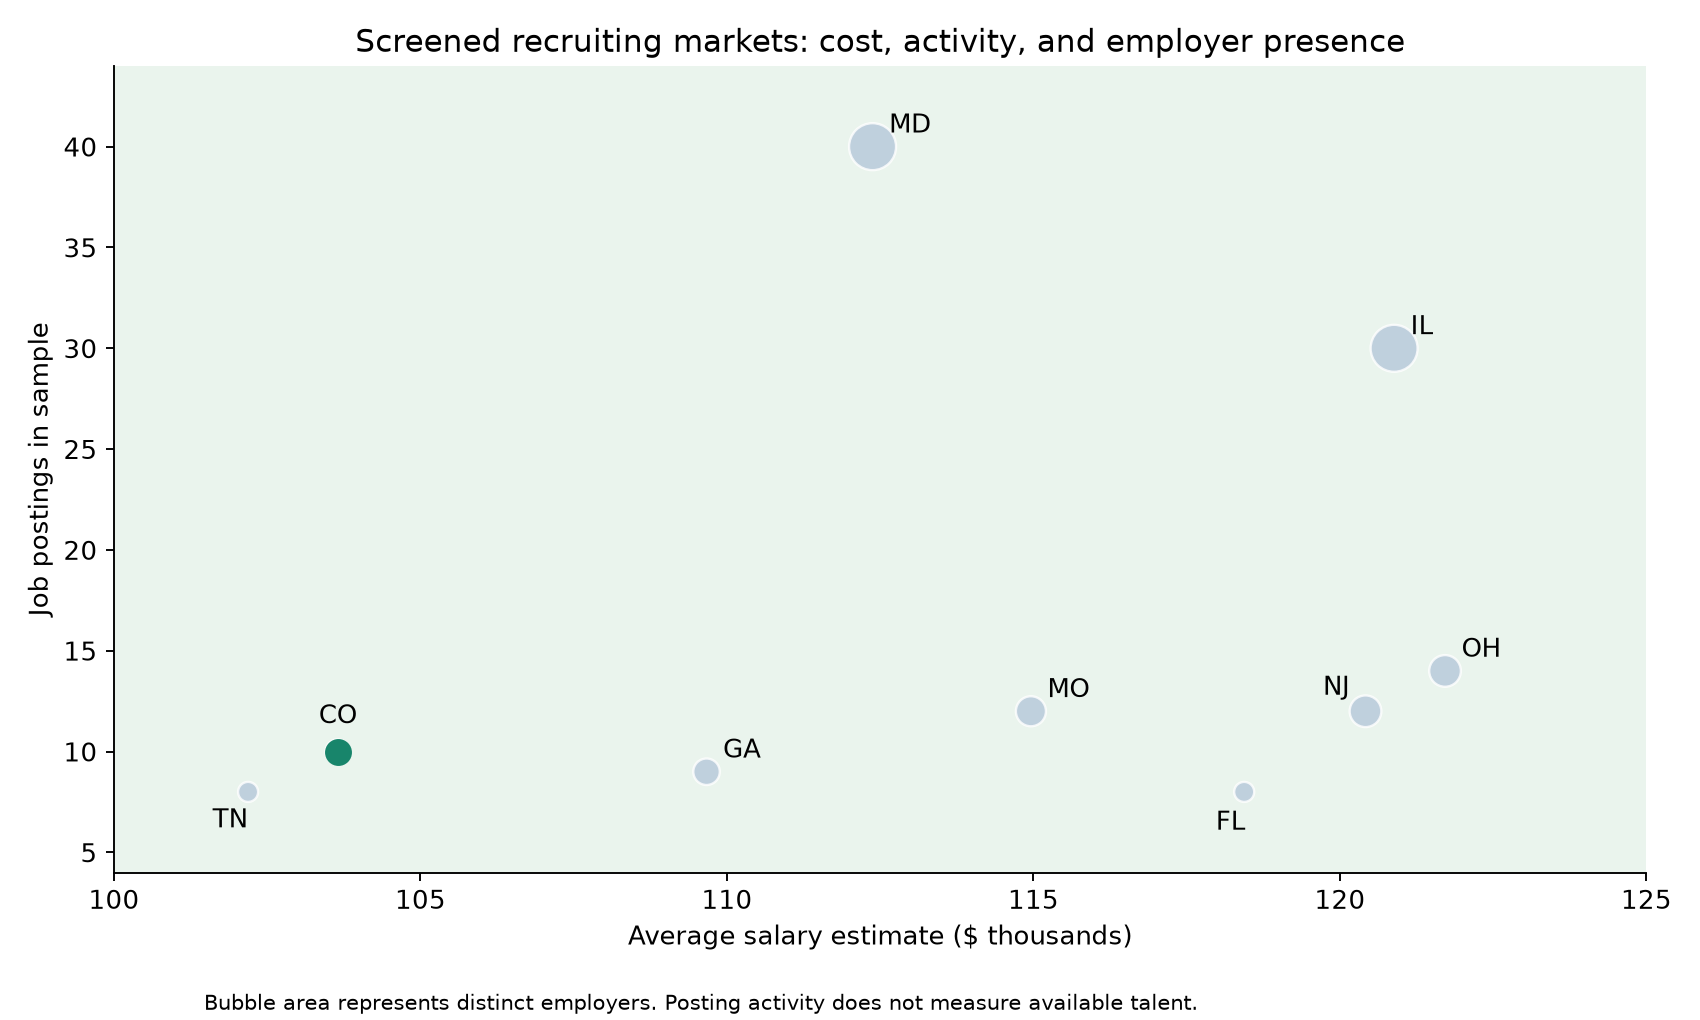

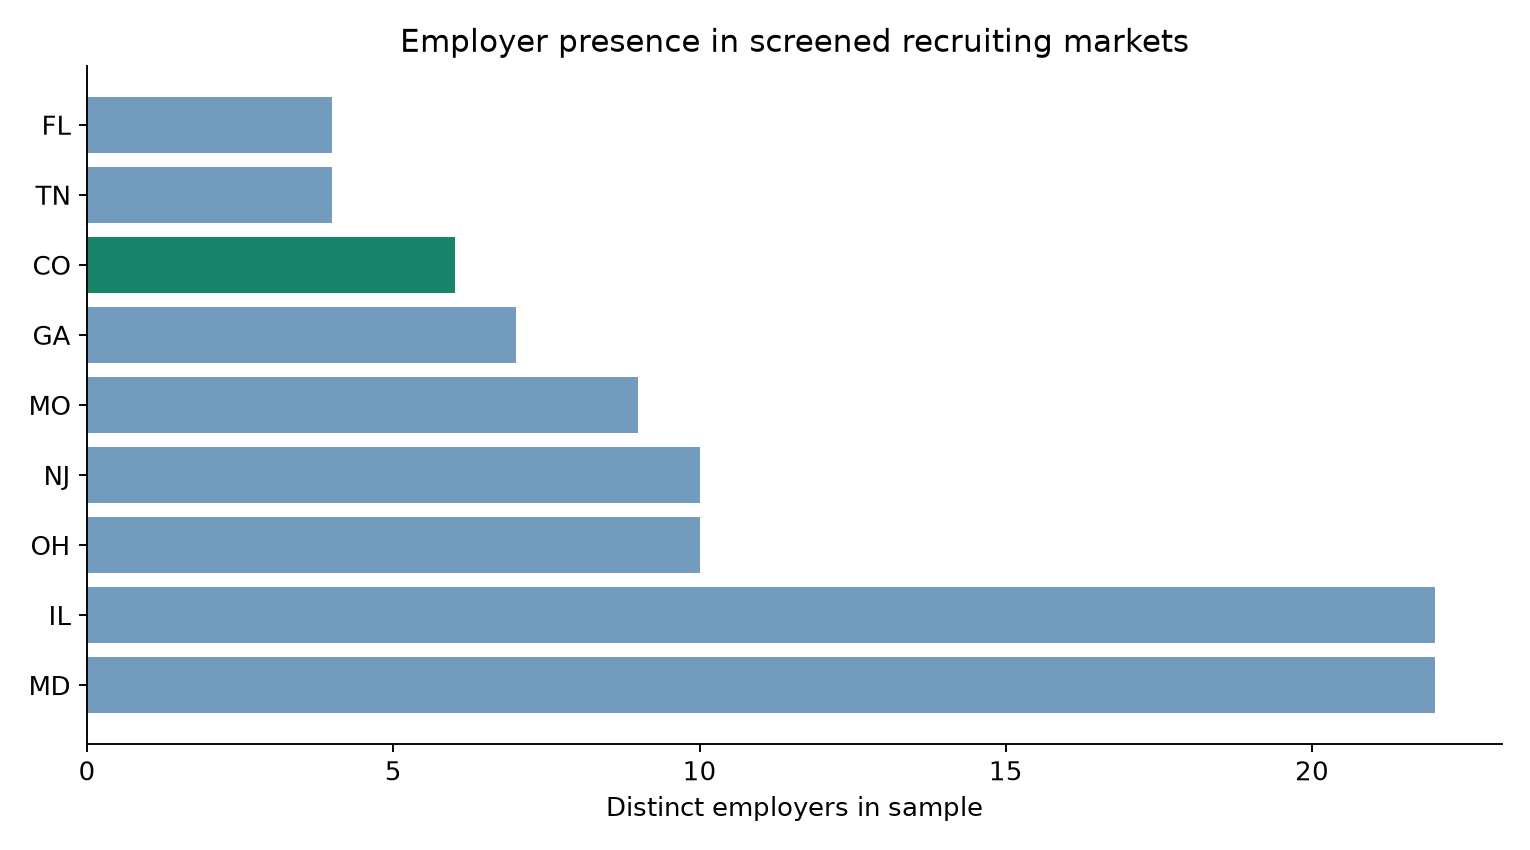

In [3]:
from IPython.display import Image, display
display(Image(filename='results/market_comparison.png'))
display(Image(filename='results/employer_comparison.png'))

## Reproducibility

Regenerated for the portfolio on October 28, 2026. See ../VALIDATION.md for comparisons with original course results. Associations and descriptive trend signals do not establish causation or guarantee future outcomes.